<a href="https://colab.research.google.com/github/aycaaozturk/AML-project/blob/main/Step_2_Counterfactual_Digital_Twin_Generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q scikit-survival xgboost lifelines

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from google.colab import drive

from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv
from sksurv.metrics import concordance_index_censored

import xgboost as xgb

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

RANDOM_STATE = 42

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
BASE_DIR = Path(
    "/content/drive/MyDrive/Uniklinikum Würzburg/AML/"
    "Output Files 2/combined_survival_model_ready_wout_protocol/"
)

TRAIN_PATH = BASE_DIR / "combined_train_survival_model_ready.csv"
VALIDATION_PATH = BASE_DIR / "combined_validation_survival_model_ready.csv"
TEST_PATH = BASE_DIR / "combined_test_survival_model_ready.csv"

DIGITAL_TWIN_DIR = BASE_DIR / "digital_twins"
DIGITAL_TWIN_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Train:", TRAIN_PATH)
print("Validation:", VALIDATION_PATH)
print("Test:", TEST_PATH)
print("Output:", DIGITAL_TWIN_DIR)

Train: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/combined_train_survival_model_ready.csv
Validation: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/combined_validation_survival_model_ready.csv
Test: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/combined_test_survival_model_ready.csv
Output: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/digital_twins


In [ ]:
train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Train: (620, 68)
Validation: (177, 68)
Test: (89, 68)


In [ ]:
NON_FEATURE_COLS = [
    "PATIENT_ID",
    "SAMPLE_ID",
    "OS_DAYS",
    "OS_EVENT"
]

FEATURE_COLS = [
    col
    for col in train_df.columns
    if col not in NON_FEATURE_COLS
]

X_train = train_df[FEATURE_COLS].copy()
X_validation = validation_df[FEATURE_COLS].copy()
X_test = test_df[FEATURE_COLS].copy()

print("Number of features:", len(FEATURE_COLS))

Number of features: 64


In [ ]:
feature_table = pd.DataFrame({
    "Feature": FEATURE_COLS
})

display(feature_table)

,Feature
0,AGE
1,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE
2,PERIPHERAL_BLASTS_PERCENTAGE
3,WBC_LOG1P
4,SEX_Female
...,...
59,FLT3_PM
60,NPM_MUTATION
61,CEBPA_MUTATION
62,WT1_MUTATION


In [ ]:
def classify_feature(feature):

    # -------------------------
    # Fixed demographics
    # -------------------------
    if (
        feature == "AGE"
        or feature.startswith("SEX_")
        or feature.startswith("RACE_")
        or feature.startswith("ETHNICITY_")
    ):
        return "Fixed demographic"

    # -------------------------
    # Risk-group classification
    # -------------------------
    if feature.startswith("RISK_GROUP"):
        return "Derived risk classification"

    # -------------------------
    # Disease-state variables
    # -------------------------
    if feature in [
        "WBC_LOG1P",
        "PERIPHERAL_BLASTS_PERCENTAGE",
        "BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE"
    ]:
        return "Disease-state / candidate counterfactual"

    # -------------------------
    # Molecular/genetic features
    # -------------------------
    genetic_keywords = [
        "MUTATION",
        "FLT3",
        "NPM",
        "CEBPA",
        "WT1",
        "MLL",
        "INV_",
        "MONOSOMY",
        "TRISOMY",
        "DEL_",
        "T_"
    ]

    if any(
        keyword in feature
        for keyword in genetic_keywords
    ):
        return "Genomic / cytogenetic"

    # -------------------------
    # Cytogenetic classifications
    # -------------------------
    if (
        feature.startswith("PRIMARY_CYTOGENETIC")
        or feature.startswith("CYTOGENETIC_COMPLEXITY")
    ):
        return "Cytogenetic classification"

    # -------------------------
    # Other
    # -------------------------
    return "Other clinical"

In [ ]:
feature_classification = pd.DataFrame({
    "Feature": FEATURE_COLS
})

feature_classification["Category"] = (
    feature_classification["Feature"]
    .apply(classify_feature)
)

display(feature_classification)

,Feature,Category
0,AGE,Fixed demographic
1,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE,Disease-state / candidate counterfactual
2,PERIPHERAL_BLASTS_PERCENTAGE,Disease-state / candidate counterfactual
3,WBC_LOG1P,Disease-state / candidate counterfactual
4,SEX_Female,Fixed demographic
...,...,...
59,FLT3_PM,Genomic / cytogenetic
60,NPM_MUTATION,Genomic / cytogenetic
61,CEBPA_MUTATION,Genomic / cytogenetic
62,WT1_MUTATION,Genomic / cytogenetic


In [ ]:
category_counts = (
    feature_classification["Category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="N_Features")
)

display(category_counts)

,Category,N_Features
0,Genomic / cytogenetic,23
1,Other clinical,14
2,Fixed demographic,11
3,Cytogenetic classification,9
4,Derived risk classification,4
5,Disease-state / candidate counterfactual,3


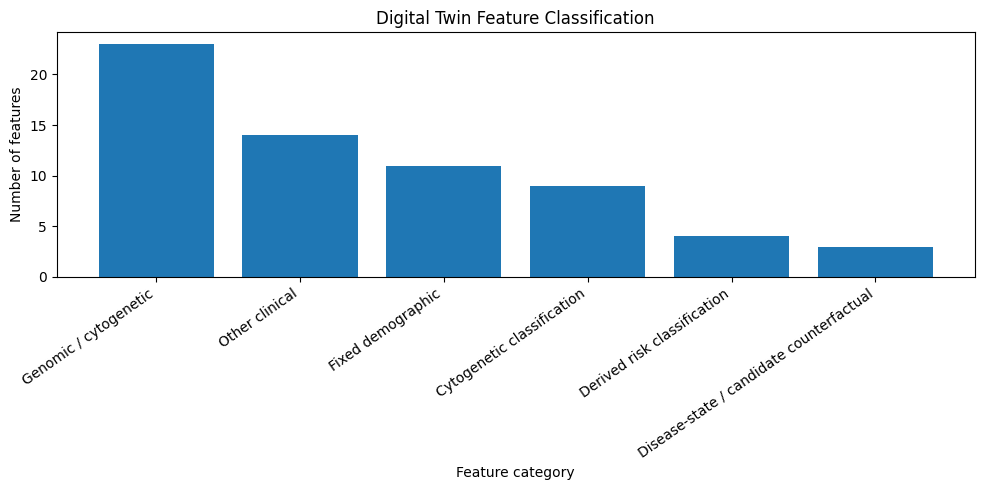

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    category_counts["Category"],
    category_counts["N_Features"]
)

plt.ylabel("Number of features")
plt.xlabel("Feature category")

plt.title(
    "Digital Twin Feature Classification"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

In [ ]:
FIXED_FEATURES = (
    feature_classification.loc[
        feature_classification["Category"].isin([
            "Fixed demographic",
            "Genomic / cytogenetic",
            "Cytogenetic classification",
            "Derived risk classification"
        ]),
        "Feature"
    ]
    .tolist()
)

CANDIDATE_COUNTERFACTUAL_FEATURES = [
    feature
    for feature in [
        "WBC_LOG1P",
        "PERIPHERAL_BLASTS_PERCENTAGE",
        "BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE"
    ]
    if feature in FEATURE_COLS
]

print("FIXED FEATURES:")
print("=" * 70)

for f in FIXED_FEATURES:
    print("-", f)

print("\nCANDIDATE COUNTERFACTUAL FEATURES:")
print("=" * 70)

for f in CANDIDATE_COUNTERFACTUAL_FEATURES:
    print("-", f)

FIXED FEATURES:
- AGE
- SEX_Female
- SEX_Male
- RACE_American Indian or Alaska Native
- RACE_Asian
- RACE_Black or African American
- RACE_Native Hawaiian or other Pacific Islander
- RACE_Other
- RACE_White
- ETHNICITY_Hispanic or Latino
- ETHNICITY_Not Hispanic or Latino
- PRIMARY_CYTOGENETIC_CODE_MLL
- PRIMARY_CYTOGENETIC_CODE_Normal
- PRIMARY_CYTOGENETIC_CODE_Other
- PRIMARY_CYTOGENETIC_CODE_inv(16)
- PRIMARY_CYTOGENETIC_CODE_t(8;21)
- RISK_GROUP_CLEAN_High
- RISK_GROUP_CLEAN_Low
- RISK_GROUP_CLEAN_Missing
- RISK_GROUP_CLEAN_Standard
- CYTOGENETIC_COMPLEXITY_GROUP_0
- CYTOGENETIC_COMPLEXITY_GROUP_1
- CYTOGENETIC_COMPLEXITY_GROUP_2
- CYTOGENETIC_COMPLEXITY_GROUP_3
- CYTOGENETIC_COMPLEXITY_GROUP_4_plus
- T_6_9
- T_8_21
- T_3_5_Q25_Q34
- T_6_11_Q27_Q23
- T_9_11_P22_Q23
- T_10_11_P11_2_Q23
- T_11_19_Q23_P13_1
- INV_16
- DEL_5Q
- DEL_7Q
- DEL_9Q
- MONOSOMY_5
- MONOSOMY_7
- TRISOMY_8
- TRISOMY_21
- MLL
- FLT3_ITD_POSITIVE
- FLT3_PM
- NPM_MUTATION
- CEBPA_MUTATION
- WT1_MUTATION
- FLT3_ITD

In [ ]:
counterfactual_policy = pd.DataFrame({

    "Feature_Group": [
        "Demographics",
        "Genomic / cytogenetic",
        "Risk classification",
        "Disease-state"
    ],

    "Examples": [
        "Age, sex, race, ethnicity",
        "FLT3, WT1, NPM, INV_16, T_8_21, monosomies",
        "Risk group",
        "WBC, peripheral blasts, bone-marrow blasts"
    ],

    "Counterfactual_Policy": [
        "Keep fixed",
        "Keep fixed initially",
        "Keep fixed / do not manipulate directly",
        "Candidate for simulation"
    ]
})

display(counterfactual_policy)

,Feature_Group,Examples,Counterfactual_Policy
0,Demographics,"Age, sex, race, ethnicity",Keep fixed
1,Genomic / cytogenetic,"FLT3, WT1, NPM, INV_16, T_8_21, monosomies",Keep fixed initially
2,Risk classification,Risk group,Keep fixed / do not manipulate directly
3,Disease-state,"WBC, peripheral blasts, bone-marrow blasts",Candidate for simulation


In [ ]:
y_train = Surv.from_arrays(
    event=train_df["OS_EVENT"].astype(bool),
    time=train_df["OS_DAYS"].astype(float)
)

y_validation = Surv.from_arrays(
    event=validation_df["OS_EVENT"].astype(bool),
    time=validation_df["OS_DAYS"].astype(float)
)

y_test = Surv.from_arrays(
    event=test_df["OS_EVENT"].astype(bool),
    time=test_df["OS_DAYS"].astype(float)
)

In [ ]:
rsf = RandomSurvivalForest(
    n_estimators=1000,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    bootstrap=True,
    n_jobs=-1,
    random_state=42
)

rsf.fit(
    X_train,
    y_train
)

print("✓ RSF trained")

✓ RSF trained


In [ ]:
XGB_PARAMS = {
    "objective": "survival:cox",
    "eval_metric": "cox-nloglik",

    "max_depth": 5,
    "min_child_weight": 1,

    "lambda": 1.0,
    "alpha": 0.0,

    "eta": 0.03,

    "subsample": 0.70,
    "colsample_bytree": 0.70,

    "tree_method": "hist",

    "seed": 42,
    "verbosity": 0
}

In [ ]:
def make_xgb_survival_label(df):

    times = df["OS_DAYS"].astype(float).values
    events = df["OS_EVENT"].astype(bool).values

    return np.where(
        events,
        times,
        -times
    )

In [ ]:
dtrain = xgb.DMatrix(
    X_train,
    label=make_xgb_survival_label(train_df)
)

dval = xgb.DMatrix(
    X_validation,
    label=make_xgb_survival_label(validation_df)
)

In [ ]:
xgb_model = xgb.train(
    params=XGB_PARAMS,
    dtrain=dtrain,
    num_boost_round=2000,

    evals=[
        (dtrain, "train"),
        (dval, "validation")
    ],

    early_stopping_rounds=100,
    verbose_eval=100
)

BEST_ITERATION = (
    xgb_model.best_iteration + 1
)

print(
    "Best iteration:",
    BEST_ITERATION
)

[0]	train-cox-nloglik:6.14276	validation-cox-nloglik:4.92361
[100]	train-cox-nloglik:5.37217	validation-cox-nloglik:4.74724
[189]	train-cox-nloglik:5.04804	validation-cox-nloglik:4.79500
Best iteration: 90


In [ ]:
def estimate_breslow_baseline_hazard(
    times,
    events,
    linear_predictor
):

    times = np.asarray(
        times,
        dtype=float
    )

    events = np.asarray(
        events,
        dtype=bool
    )

    linear_predictor = np.asarray(
        linear_predictor,
        dtype=float
    )

    exp_lp = np.exp(
        np.clip(
            linear_predictor,
            -50,
            50
        )
    )

    event_times = np.sort(
        np.unique(
            times[events]
        )
    )

    cumulative_hazard = []

    H0 = 0.0

    for t in event_times:

        deaths = np.sum(
            (times == t)
            &
            events
        )

        risk_set = (
            times >= t
        )

        denominator = np.sum(
            exp_lp[risk_set]
        )

        if denominator > 0:

            H0 += (
                deaths
                /
                denominator
            )

        cumulative_hazard.append(
            H0
        )

    return (
        event_times,
        np.asarray(
            cumulative_hazard
        )
    )

In [ ]:
xgb_margin_train = xgb_model.predict(
    dtrain,
    output_margin=True,
    iteration_range=(
        0,
        BEST_ITERATION
    )
)

baseline_times, baseline_H0 = (
    estimate_breslow_baseline_hazard(
        train_df["OS_DAYS"].values,
        train_df["OS_EVENT"].astype(bool).values,
        xgb_margin_train
    )
)

In [ ]:
def get_baseline_hazard_at_time(
    horizon,
    baseline_times,
    baseline_H0
):

    idx = np.searchsorted(
        baseline_times,
        horizon,
        side="right"
    ) - 1

    if idx < 0:
        return 0.0

    return baseline_H0[idx]

In [ ]:
def predict_xgb_survival(
    model,
    X,
    horizon
):

    dmatrix = xgb.DMatrix(X)

    margin = model.predict(
        dmatrix,
        output_margin=True,
        iteration_range=(
            0,
            BEST_ITERATION
        )
    )

    relative_hazard = np.exp(
        np.clip(
            margin,
            -50,
            50
        )
    )

    H0_t = get_baseline_hazard_at_time(
        horizon,
        baseline_times,
        baseline_H0
    )

    return np.exp(
        -H0_t
        *
        relative_hazard
    )

In [ ]:
HORIZONS = {
    "1Y": 365,
    "2Y": 730,
    "3Y": 1095
}

In [ ]:
def predict_digital_twins(X):

    X = X[FEATURE_COLS].copy()

    # =========================
    # RSF
    # =========================

    rsf_risk = rsf.predict(X)

    rsf_functions = (
        rsf.predict_survival_function(X)
    )

    results = pd.DataFrame({
        "RSF_RISK": rsf_risk
    })

    for label, horizon in HORIZONS.items():

        results[
            f"RSF_SURVIVAL_{label}"
        ] = [
            float(fn(horizon))
            for fn in rsf_functions
        ]

    # =========================
    # XGBoost
    # =========================

    dmatrix = xgb.DMatrix(X)

    xgb_risk = xgb_model.predict(
        dmatrix,
        iteration_range=(
            0,
            BEST_ITERATION
        )
    )

    results["XGB_RISK"] = xgb_risk

    for label, horizon in HORIZONS.items():

        results[
            f"XGB_SURVIVAL_{label}"
        ] = predict_xgb_survival(
            xgb_model,
            X,
            horizon
        )

    return results

In [ ]:
baseline_predictions = (
    predict_digital_twins(
        X_test
    )
)

baseline_predictions.insert(
    0,
    "PATIENT_ID",
    test_df["PATIENT_ID"].values
)

display(
    baseline_predictions
    .head(10)
    .round(4)
)

,PATIENT_ID,RSF_RISK,RSF_SURVIVAL_1Y,RSF_SURVIVAL_2Y,RSF_SURVIVAL_3Y,XGB_RISK,XGB_SURVIVAL_1Y,XGB_SURVIVAL_2Y,XGB_SURVIVAL_3Y
0,TARGET-21-PANVPB,52.6763,0.8140,0.6763,0.6177,1.6386,0.7870,0.6052,0.5401
1,TARGET-20-PASHZX,41.1425,0.8559,0.7369,0.6902,1.4974,0.8034,0.6319,0.5695
2,TARGET-20-PASKFN,20.0239,0.9209,0.8618,0.8457,0.3682,0.9476,0.8933,0.8707
3,TARGET-20-PATAST,24.1250,0.9020,0.8345,0.8199,0.4170,0.9409,0.8800,0.8549
4,TARGET-20-PASYRE,43.2527,0.8396,0.7318,0.6792,1.0414,0.8588,0.7267,0.6760
5,TARGET-20-PARHJV,19.9677,0.9299,0.8581,0.8433,0.3109,0.9556,0.9091,0.8897
6,TARGET-20-PAKLPD,41.9251,0.8408,0.7333,0.6802,0.6175,0.9137,0.8276,0.7928
7,TARGET-20-PARSRR,43.4064,0.8434,0.7294,0.6747,1.3278,0.8236,0.6657,0.6070
8,TARGET-20-PATMCW,72.9074,0.7424,0.6129,0.5419,2.6697,0.6769,0.4412,0.3666
9,TARGET-20-PATEMK,22.0093,0.9272,0.8363,0.8262,0.4726,0.9333,0.8652,0.8372


In [ ]:
counterfactual_reference = []

for feature in CANDIDATE_COUNTERFACTUAL_FEATURES:

    values = (
        X_train[feature]
        .dropna()
    )

    counterfactual_reference.append({

        "Feature":
            feature,

        "Train_Min":
            values.min(),

        "Q10":
            values.quantile(0.10),

        "Q25":
            values.quantile(0.25),

        "Median":
            values.median(),

        "Q75":
            values.quantile(0.75),

        "Q90":
            values.quantile(0.90),

        "Train_Max":
            values.max()
    })

In [ ]:
counterfactual_reference_df = pd.DataFrame(
    counterfactual_reference
)

display(
    counterfactual_reference_df
    .round(4)
)

,Feature,Train_Min,Q10,Q25,Median,Q75,Q90,Train_Max
0,WBC_LOG1P,-2.5336,-1.3006,-0.7551,-0.0399,0.7585,1.3664,2.2463
1,PERIPHERAL_BLASTS_PERCENTAGE,-1.4471,-1.4189,-0.9452,0.0509,0.9058,1.3450,1.6587
2,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE,-2.6787,-1.4861,-0.7035,0.2430,0.8452,1.1097,1.4364


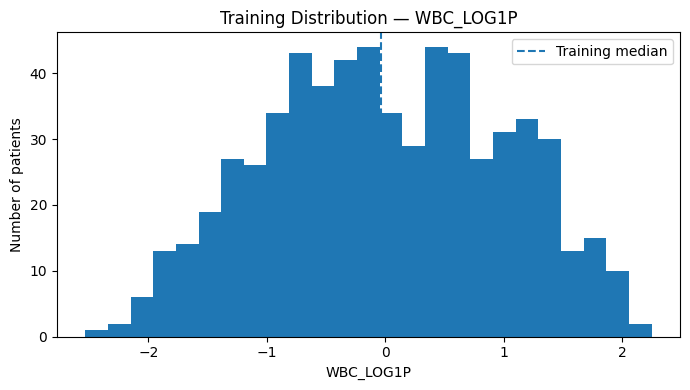

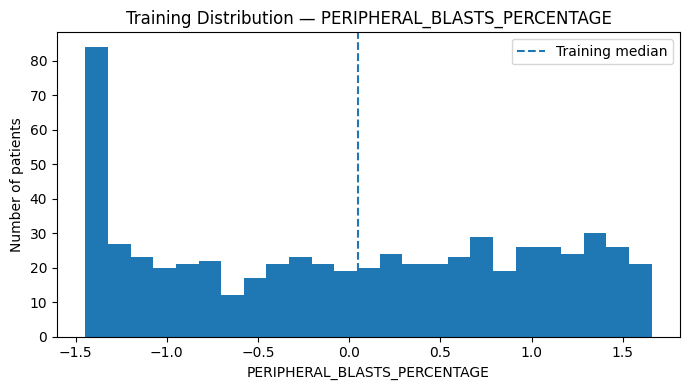

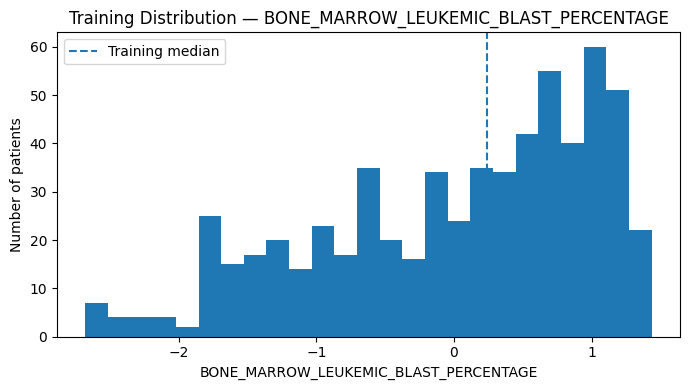

In [ ]:
for feature in CANDIDATE_COUNTERFACTUAL_FEATURES:

    plt.figure(
        figsize=(7, 4)
    )

    plt.hist(
        X_train[feature].dropna(),
        bins=25
    )

    plt.axvline(
        X_train[feature].median(),
        linestyle="--",
        label="Training median"
    )

    plt.xlabel(feature)
    plt.ylabel("Number of patients")

    plt.title(
        f"Training Distribution — {feature}"
    )

    plt.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
LOWER_BURDEN_TARGETS = {
    feature:
        X_train[feature].median()

    for feature
    in CANDIDATE_COUNTERFACTUAL_FEATURES
}

print(
    "Counterfactual target values:"
)

for feature, value in LOWER_BURDEN_TARGETS.items():

    print(
        feature,
        "→",
        round(value, 4)
    )

Counterfactual target values:
WBC_LOG1P → -0.0399
PERIPHERAL_BLASTS_PERCENTAGE → 0.0509
BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE → 0.243


In [ ]:
def create_lower_burden_twin(
    patient_features
):

    cf = patient_features.copy()

    changes = []

    for feature, target in LOWER_BURDEN_TARGETS.items():

        original = float(
            cf[feature]
        )

        # Only lower the feature
        # if it is currently above
        # the training median.

        if original > target:

            cf[feature] = target

            changes.append({
                "Feature": feature,
                "Original": original,
                "Counterfactual": target,
                "Change": target - original
            })

    return (
        cf,
        pd.DataFrame(changes)
    )

In [ ]:
PATIENT_INDEX = 0

patient_id = (
    test_df.iloc[
        PATIENT_INDEX
    ]["PATIENT_ID"]
)

baseline_patient = (
    X_test.iloc[
        PATIENT_INDEX
    ].copy()
)

counterfactual_patient, changes = (
    create_lower_burden_twin(
        baseline_patient
    )
)

print(
    "Patient:",
    patient_id
)

print(
    "\nModified variables:"
)

display(
    changes.round(4)
)

Patient: TARGET-21-PANVPB

Modified variables:


,Feature,Original,Counterfactual,Change
0,WBC_LOG1P,0.0554,-0.0399,-0.0953
1,PERIPHERAL_BLASTS_PERCENTAGE,1.3136,0.0509,-1.2627
2,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE,0.9138,0.2430,-0.6708


In [ ]:
fixed_changes = []

for feature in FIXED_FEATURES:

    if (
        baseline_patient[feature]
        !=
        counterfactual_patient[feature]
    ):

        fixed_changes.append(
            feature
        )

print(
    "Fixed features changed:",
    fixed_changes
)

assert len(fixed_changes) == 0

print(
    "✓ Fixed characteristics unchanged."
)

Fixed features changed: []
✓ Fixed characteristics unchanged.


In [ ]:
baseline_input = pd.DataFrame(
    [baseline_patient],
    columns=FEATURE_COLS
)

counterfactual_input = pd.DataFrame(
    [counterfactual_patient],
    columns=FEATURE_COLS
)

baseline_result = (
    predict_digital_twins(
        baseline_input
    )
)

counterfactual_result = (
    predict_digital_twins(
        counterfactual_input
    )
)

In [ ]:
patient_comparison = []

for model in [
    "RSF",
    "XGB"
]:

    for horizon in [
        "1Y",
        "2Y",
        "3Y"
    ]:

        column = (
            f"{model}_SURVIVAL_{horizon}"
        )

        baseline_value = (
            baseline_result[
                column
            ].iloc[0]
        )

        counterfactual_value = (
            counterfactual_result[
                column
            ].iloc[0]
        )

        patient_comparison.append({

            "Model":
                model,

            "Horizon":
                horizon,

            "Baseline_Survival":
                baseline_value,

            "Counterfactual_Survival":
                counterfactual_value,

            "Absolute_Change":
                (
                    counterfactual_value
                    -
                    baseline_value
                )
        })

In [ ]:
patient_comparison_df = pd.DataFrame(
    patient_comparison
)

display(
    patient_comparison_df
    .round(4)
)

,Model,Horizon,Baseline_Survival,Counterfactual_Survival,Absolute_Change
0,RSF,1Y,0.8140,0.8245,0.0105
1,RSF,2Y,0.6763,0.6960,0.0196
2,RSF,3Y,0.6177,0.6354,0.0177
3,XGB,1Y,0.7870,0.7818,-0.0052
4,XGB,2Y,0.6052,0.5968,-0.0084
5,XGB,3Y,0.5401,0.5309,-0.0092


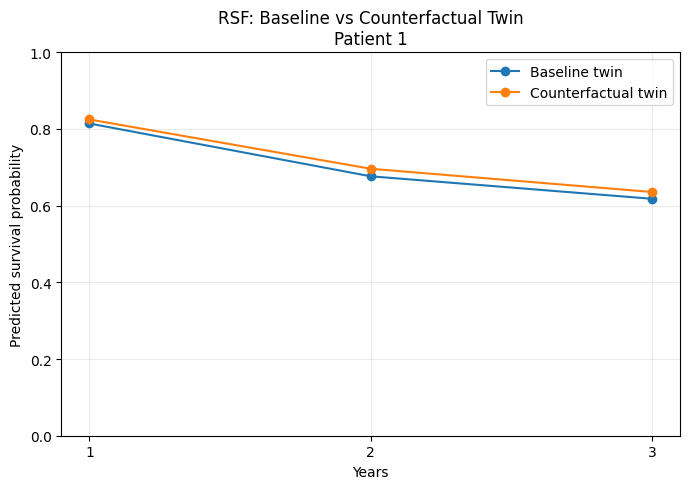

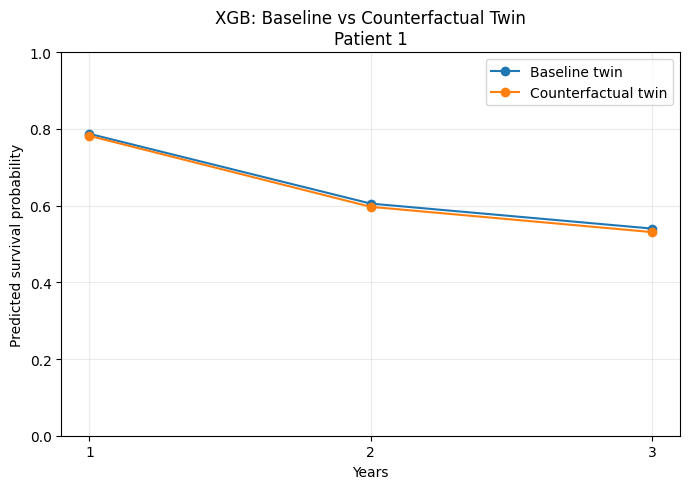

In [ ]:
for model in [
    "RSF",
    "XGB"
]:

    model_df = (
        patient_comparison_df[
            patient_comparison_df[
                "Model"
            ] == model
        ]
    )

    years = [
        1,
        2,
        3
    ]

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        years,
        model_df[
            "Baseline_Survival"
        ],
        marker="o",
        label="Baseline twin"
    )

    plt.plot(
        years,
        model_df[
            "Counterfactual_Survival"
        ],
        marker="o",
        label="Counterfactual twin"
    )

    plt.xlabel(
        "Years"
    )

    plt.ylabel(
        "Predicted survival probability"
    )

    plt.title(
        f"{model}: Baseline vs Counterfactual Twin\n"
        f"Patient {PATIENT_INDEX + 1}"
    )

    plt.xticks(
        [1, 2, 3]
    )

    plt.ylim(
        0,
        1
    )

    plt.legend()

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()

    plt.show()

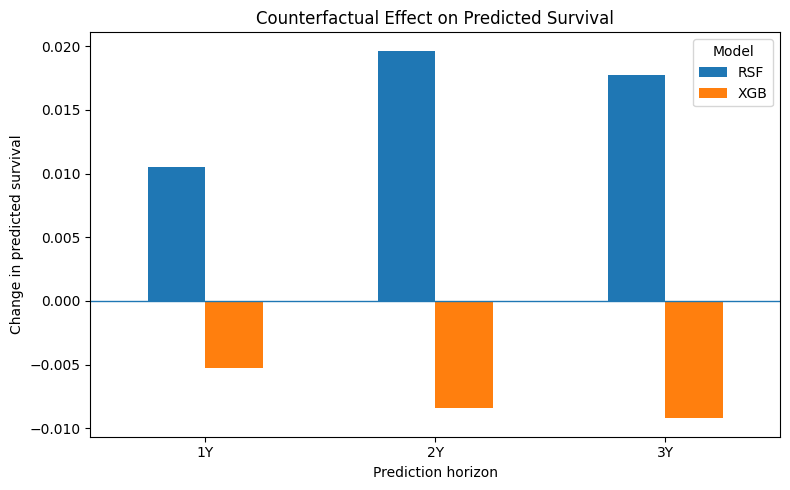

In [ ]:
plot_df = (
    patient_comparison_df
    .pivot(
        index="Horizon",
        columns="Model",
        values="Absolute_Change"
    )
    .reindex([
        "1Y",
        "2Y",
        "3Y"
    ])
)

plot_df.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.axhline(
    0,
    linewidth=1
)

plt.ylabel(
    "Change in predicted survival"
)

plt.xlabel(
    "Prediction horizon"
)

plt.title(
    "Counterfactual Effect on Predicted Survival"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [ ]:
changes_for_display = (
    changes.copy()
)

if len(changes_for_display) > 0:

    changes_for_display[
        "Absolute_Change"
    ] = (
        changes_for_display[
            "Counterfactual"
        ]
        -
        changes_for_display[
            "Original"
        ]
    )

display(
    changes_for_display
    .round(4)
)

,Feature,Original,Counterfactual,Change,Absolute_Change
0,WBC_LOG1P,0.0554,-0.0399,-0.0953,-0.0953
1,PERIPHERAL_BLASTS_PERCENTAGE,1.3136,0.0509,-1.2627,-1.2627
2,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE,0.9138,0.2430,-0.6708,-0.6708


In [ ]:
all_counterfactual_inputs = []

all_changes = []

for i in range(
    len(X_test)
):

    baseline_patient = (
        X_test.iloc[i]
        .copy()
    )

    cf_patient, changes_i = (
        create_lower_burden_twin(
            baseline_patient
        )
    )

    all_counterfactual_inputs.append(
        cf_patient
    )

    if len(changes_i) > 0:

        changes_i[
            "PATIENT_ID"
        ] = (
            test_df.iloc[i][
                "PATIENT_ID"
            ]
        )

        all_changes.append(
            changes_i
        )

In [ ]:
X_test_counterfactual = pd.DataFrame(
    all_counterfactual_inputs
)

X_test_counterfactual = (
    X_test_counterfactual[
        FEATURE_COLS
    ]
)

print(
    "Counterfactual test shape:",
    X_test_counterfactual.shape
)

Counterfactual test shape: (89, 64)


In [ ]:
counterfactual_predictions = (
    predict_digital_twins(
        X_test_counterfactual
    )
)

counterfactual_predictions.insert(
    0,
    "PATIENT_ID",
    test_df[
        "PATIENT_ID"
    ].values
)

display(
    counterfactual_predictions
    .head(10)
    .round(4)
)

,PATIENT_ID,RSF_RISK,RSF_SURVIVAL_1Y,RSF_SURVIVAL_2Y,RSF_SURVIVAL_3Y,XGB_RISK,XGB_SURVIVAL_1Y,XGB_SURVIVAL_2Y,XGB_SURVIVAL_3Y
0,TARGET-21-PANVPB,49.5167,0.8245,0.6960,0.6354,1.6844,0.7818,0.5968,0.5309
1,TARGET-20-PASHZX,41.1425,0.8559,0.7369,0.6902,1.4974,0.8034,0.6319,0.5695
2,TARGET-20-PASKFN,20.0239,0.9209,0.8618,0.8457,0.3682,0.9476,0.8933,0.8707
3,TARGET-20-PATAST,23.8334,0.9034,0.8360,0.8216,0.4425,0.9374,0.8732,0.8468
4,TARGET-20-PASYRE,42.4596,0.8429,0.7356,0.6830,0.9903,0.8653,0.7382,0.6892
5,TARGET-20-PARHJV,15.7435,0.9451,0.8830,0.8720,0.2958,0.9577,0.9133,0.8948
6,TARGET-20-PAKLPD,39.2764,0.8539,0.7464,0.6932,0.6274,0.9124,0.8251,0.7899
7,TARGET-20-PARSRR,43.4064,0.8434,0.7294,0.6747,1.3278,0.8236,0.6657,0.6070
8,TARGET-20-PATMCW,72.7315,0.7434,0.6118,0.5419,3.2336,0.6234,0.3712,0.2965
9,TARGET-20-PATEMK,19.7448,0.9318,0.8553,0.8449,0.3911,0.9444,0.8870,0.8633


In [ ]:
baseline_all = (
    predict_digital_twins(
        X_test
    )
)

baseline_all.insert(
    0,
    "PATIENT_ID",
    test_df[
        "PATIENT_ID"
    ].values
)

In [ ]:
digital_twin_comparison = pd.DataFrame({
    "PATIENT_ID":
        test_df["PATIENT_ID"].values
})

In [ ]:
for model in [
    "RSF",
    "XGB"
]:

    for horizon in [
        "1Y",
        "2Y",
        "3Y"
    ]:

        column = (
            f"{model}_SURVIVAL_{horizon}"
        )

        digital_twin_comparison[
            f"{model}_BASELINE_{horizon}"
        ] = (
            baseline_all[column]
            .values
        )

        digital_twin_comparison[
            f"{model}_CF_{horizon}"
        ] = (
            counterfactual_predictions[
                column
            ].values
        )

        digital_twin_comparison[
            f"{model}_DELTA_{horizon}"
        ] = (
            digital_twin_comparison[
                f"{model}_CF_{horizon}"
            ]
            -
            digital_twin_comparison[
                f"{model}_BASELINE_{horizon}"
            ]
        )

In [ ]:
display(
    digital_twin_comparison
    .head(10)
    .round(4)
)

,PATIENT_ID,RSF_BASELINE_1Y,RSF_CF_1Y,RSF_DELTA_1Y,RSF_BASELINE_2Y,RSF_CF_2Y,RSF_DELTA_2Y,RSF_BASELINE_3Y,RSF_CF_3Y,RSF_DELTA_3Y,XGB_BASELINE_1Y,XGB_CF_1Y,XGB_DELTA_1Y,XGB_BASELINE_2Y,XGB_CF_2Y,XGB_DELTA_2Y,XGB_BASELINE_3Y,XGB_CF_3Y,XGB_DELTA_3Y
0,TARGET-21-PANVPB,0.8140,0.8245,0.0105,0.6763,0.6960,0.0196,0.6177,0.6354,0.0177,0.7870,0.7818,-0.0052,0.6052,0.5968,-0.0084,0.5401,0.5309,-0.0092
1,TARGET-20-PASHZX,0.8559,0.8559,0.0000,0.7369,0.7369,0.0000,0.6902,0.6902,0.0000,0.8034,0.8034,0.0000,0.6319,0.6319,0.0000,0.5695,0.5695,0.0000
2,TARGET-20-PASKFN,0.9209,0.9209,0.0000,0.8618,0.8618,0.0000,0.8457,0.8457,0.0000,0.9476,0.9476,0.0000,0.8933,0.8933,0.0000,0.8707,0.8707,0.0000
3,TARGET-20-PATAST,0.9020,0.9034,0.0014,0.8345,0.8360,0.0016,0.8199,0.8216,0.0017,0.9409,0.9374,-0.0035,0.8800,0.8732,-0.0068,0.8549,0.8468,-0.0081
4,TARGET-20-PASYRE,0.8396,0.8429,0.0033,0.7318,0.7356,0.0037,0.6792,0.6830,0.0037,0.8588,0.8653,0.0064,0.7267,0.7382,0.0115,0.6760,0.6892,0.0131
5,TARGET-20-PARHJV,0.9299,0.9451,0.0152,0.8581,0.8830,0.0249,0.8433,0.8720,0.0287,0.9556,0.9577,0.0021,0.9091,0.9133,0.0042,0.8897,0.8948,0.0051
6,TARGET-20-PAKLPD,0.8408,0.8539,0.0131,0.7333,0.7464,0.0131,0.6802,0.6932,0.0130,0.9137,0.9124,-0.0013,0.8276,0.8251,-0.0025,0.7928,0.7899,-0.0029
7,TARGET-20-PARSRR,0.8434,0.8434,0.0000,0.7294,0.7294,0.0000,0.6747,0.6747,0.0000,0.8236,0.8236,0.0000,0.6657,0.6657,0.0000,0.6070,0.6070,0.0000
8,TARGET-20-PATMCW,0.7424,0.7434,0.0011,0.6129,0.6118,-0.0012,0.5419,0.5419,0.0001,0.6769,0.6234,-0.0536,0.4412,0.3712,-0.0700,0.3666,0.2965,-0.0700
9,TARGET-20-PATEMK,0.9272,0.9318,0.0046,0.8363,0.8553,0.0190,0.8262,0.8449,0.0187,0.9333,0.9444,0.0112,0.8652,0.8870,0.0219,0.8372,0.8633,0.0260


In [ ]:
summary_rows = []

for model in [
    "RSF",
    "XGB"
]:

    for horizon in [
        "1Y",
        "2Y",
        "3Y"
    ]:

        delta = (
            digital_twin_comparison[
                f"{model}_DELTA_{horizon}"
            ]
        )

        summary_rows.append({

            "Model":
                model,

            "Horizon":
                horizon,

            "Mean_Delta":
                delta.mean(),

            "Median_Delta":
                delta.median(),

            "SD_Delta":
                delta.std(),

            "Min_Delta":
                delta.min(),

            "Max_Delta":
                delta.max(),

            "Pct_Positive":
                (
                    delta > 0
                ).mean() * 100
        })

In [ ]:
population_summary = pd.DataFrame(
    summary_rows
)

display(
    population_summary
    .round(4)
)

,Model,Horizon,Mean_Delta,Median_Delta,SD_Delta,Min_Delta,Max_Delta,Pct_Positive
0,RSF,1Y,0.0099,0.0016,0.0187,-0.0025,0.1144,60.6742
1,RSF,2Y,0.0157,0.0024,0.0269,-0.0012,0.1582,59.5506
2,RSF,3Y,0.0159,0.0023,0.0273,-0.0014,0.1603,62.9213
3,XGB,1Y,0.0077,0.0000,0.0408,-0.1705,0.2162,38.2022
4,XGB,2Y,0.0131,0.0000,0.0640,-0.2619,0.3308,38.2022
5,XGB,3Y,0.0148,0.0000,0.0698,-0.2812,0.3549,38.2022


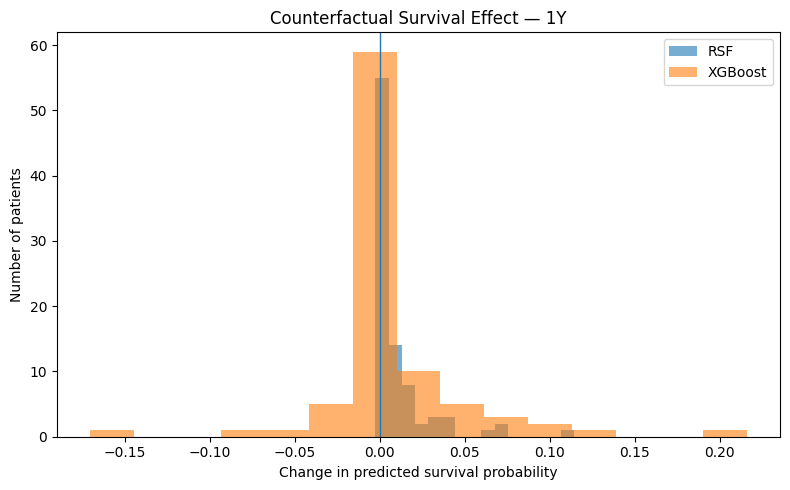

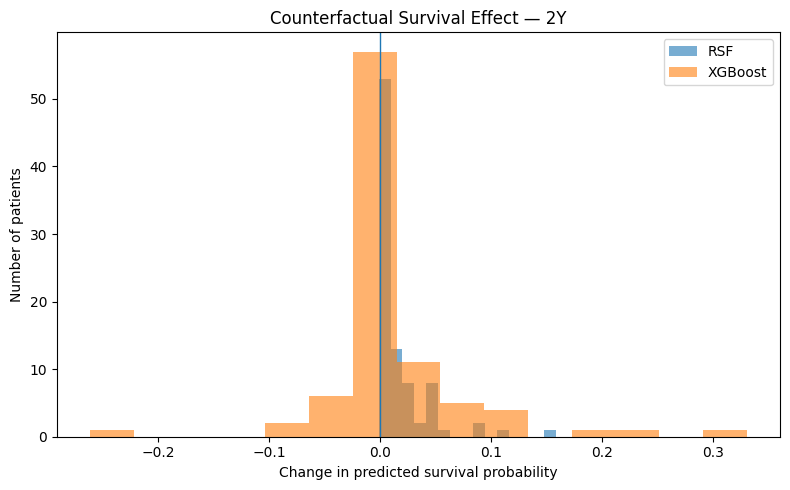

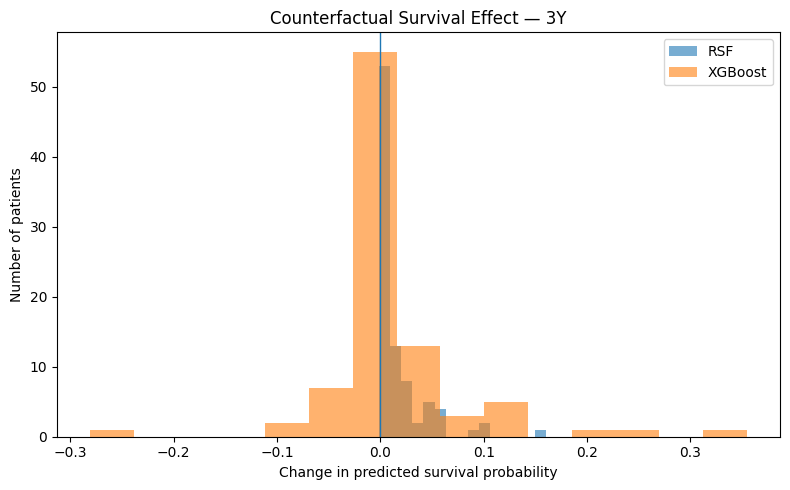

In [ ]:
for horizon in [
    "1Y",
    "2Y",
    "3Y"
]:

    plt.figure(
        figsize=(8, 5)
    )

    plt.hist(
        digital_twin_comparison[
            f"RSF_DELTA_{horizon}"
        ],
        bins=15,
        alpha=0.6,
        label="RSF"
    )

    plt.hist(
        digital_twin_comparison[
            f"XGB_DELTA_{horizon}"
        ],
        bins=15,
        alpha=0.6,
        label="XGBoost"
    )

    plt.axvline(
        0,
        linewidth=1
    )

    plt.xlabel(
        "Change in predicted survival probability"
    )

    plt.ylabel(
        "Number of patients"
    )

    plt.title(
        f"Counterfactual Survival Effect — {horizon}"
    )

    plt.legend()

    plt.tight_layout()

    plt.show()

In [ ]:
agreement_rows = []

for horizon in [
    "1Y",
    "2Y",
    "3Y"
]:

    rsf_delta = (
        digital_twin_comparison[
            f"RSF_DELTA_{horizon}"
        ]
    )

    xgb_delta = (
        digital_twin_comparison[
            f"XGB_DELTA_{horizon}"
        ]
    )

    correlation = (
        rsf_delta.corr(
            xgb_delta
        )
    )

    same_direction = (
        np.sign(rsf_delta)
        ==
        np.sign(xgb_delta)
    ).mean()

    mean_abs_difference = (
        np.abs(
            rsf_delta
            -
            xgb_delta
        )
        .mean()
    )

    agreement_rows.append({

        "Horizon":
            horizon,

        "Delta_Correlation":
            correlation,

        "Same_Direction_Percent":
            same_direction * 100,

        "Mean_Absolute_Delta_Difference":
            mean_abs_difference
    })

In [ ]:
counterfactual_agreement = (
    pd.DataFrame(
        agreement_rows
    )
)

display(
    counterfactual_agreement
    .round(4)
)

,Horizon,Delta_Correlation,Same_Direction_Percent,Mean_Absolute_Delta_Difference
0,1Y,0.7084,73.0337,0.0138
1,2Y,0.7396,75.2809,0.0219
2,3Y,0.7388,69.6629,0.0245


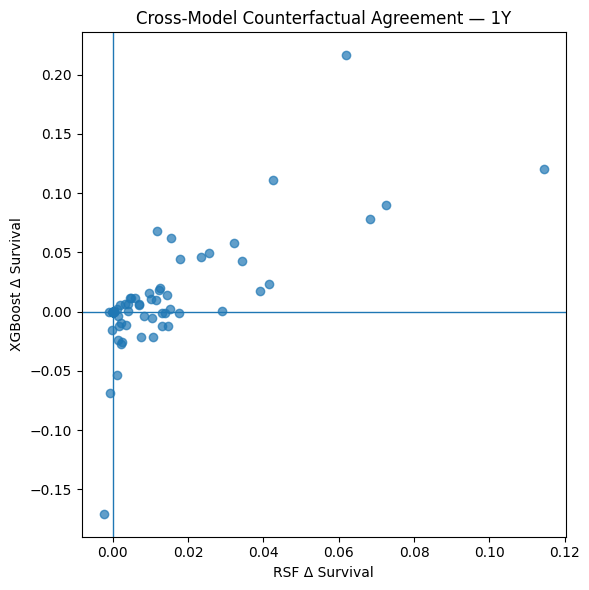

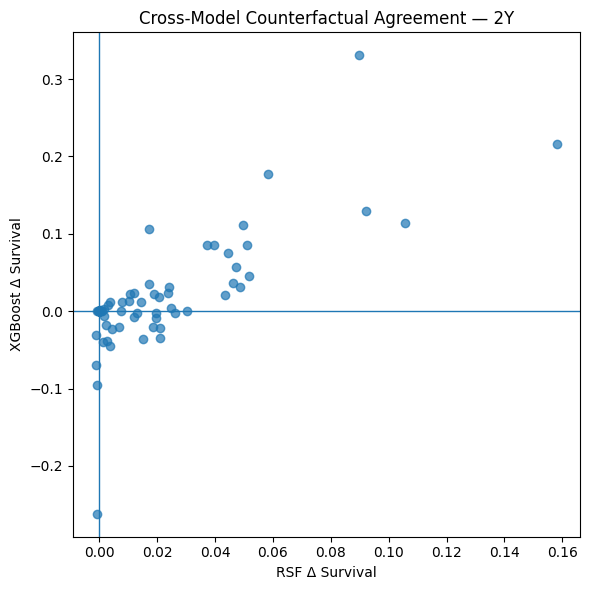

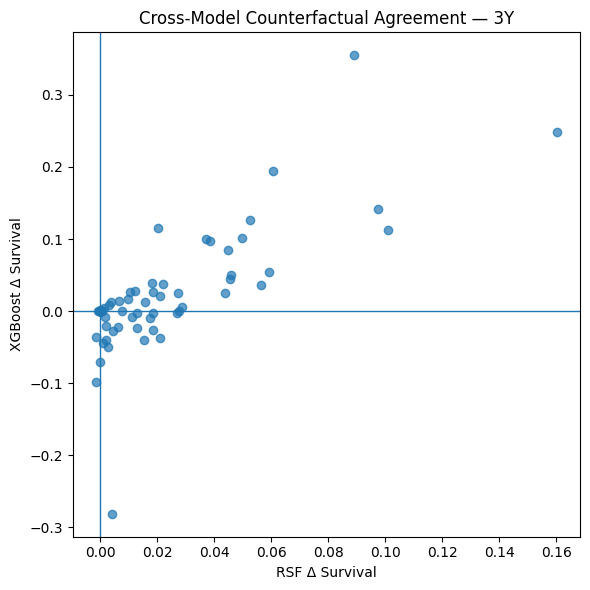

In [ ]:
for horizon in [
    "1Y",
    "2Y",
    "3Y"
]:

    x = (
        digital_twin_comparison[
            f"RSF_DELTA_{horizon}"
        ]
    )

    y = (
        digital_twin_comparison[
            f"XGB_DELTA_{horizon}"
        ]
    )

    plt.figure(
        figsize=(6, 6)
    )

    plt.scatter(
        x,
        y,
        alpha=0.7
    )

    plt.axhline(
        0,
        linewidth=1
    )

    plt.axvline(
        0,
        linewidth=1
    )

    plt.xlabel(
        "RSF Δ Survival"
    )

    plt.ylabel(
        "XGBoost Δ Survival"
    )

    plt.title(
        f"Cross-Model Counterfactual Agreement — {horizon}"
    )

    plt.tight_layout()

    plt.show()

In [ ]:
largest_effects = (
    digital_twin_comparison[
        [
            "PATIENT_ID",
            "RSF_DELTA_3Y",
            "XGB_DELTA_3Y"
        ]
    ]
    .copy()
)

largest_effects[
    "Mean_3Y_Effect"
] = (
    largest_effects[
        [
            "RSF_DELTA_3Y",
            "XGB_DELTA_3Y"
        ]
    ]
    .mean(
        axis=1
    )
)

largest_effects = (
    largest_effects
    .sort_values(
        "Mean_3Y_Effect",
        ascending=False
    )
)

display(
    largest_effects
    .head(10)
    .round(4)
)

,PATIENT_ID,RSF_DELTA_3Y,XGB_DELTA_3Y,Mean_3Y_Effect
24,TARGET-20-PARSXZ,0.0893,0.3549,0.2221
51,TARGET-20-PAKKIM,0.1603,0.2486,0.2045
73,TARGET-20-PASICM,0.0605,0.1943,0.1274
44,TARGET-21-PASFHK,0.0975,0.1422,0.1198
29,TARGET-20-PATGIG,0.1009,0.1119,0.1064
11,TARGET-20-PASDFK,0.0528,0.1270,0.0899
81,TARGET-20-PASLSI,0.0498,0.1018,0.0758
32,TARGET-20-PASEGC,0.0374,0.1004,0.0689
30,TARGET-20-PATFRY,0.0385,0.0966,0.0675
78,TARGET-20-PATGXW,0.0203,0.1147,0.0675


In [ ]:
plausibility_rows = []

for feature in CANDIDATE_COUNTERFACTUAL_FEATURES:

    train_min = (
        X_train[feature]
        .min()
    )

    train_max = (
        X_train[feature]
        .max()
    )

    cf_values = (
        X_test_counterfactual[
            feature
        ]
    )

    outside = (
        (cf_values < train_min)
        |
        (cf_values > train_max)
    )

    plausibility_rows.append({

        "Feature":
            feature,

        "Training_Min":
            train_min,

        "Training_Max":
            train_max,

        "CF_Min":
            cf_values.min(),

        "CF_Max":
            cf_values.max(),

        "Outside_Training_Range_N":
            outside.sum()
    })

In [ ]:
plausibility_df = pd.DataFrame(
    plausibility_rows
)

display(
    plausibility_df
    .round(4)
)

,Feature,Training_Min,Training_Max,CF_Min,CF_Max,Outside_Training_Range_N
0,WBC_LOG1P,-2.5336,2.2463,-2.3624,-0.0399,0
1,PERIPHERAL_BLASTS_PERCENTAGE,-1.4471,1.6587,-1.4471,0.0509,0
2,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE,-2.6787,1.4364,-2.3083,0.2430,0


In [ ]:
digital_twin_comparison.to_csv(
    DIGITAL_TWIN_DIR
    /
    "counterfactual_digital_twins_step2.csv",
    index=False
)

population_summary.to_csv(
    DIGITAL_TWIN_DIR
    /
    "counterfactual_population_summary.csv",
    index=False
)

counterfactual_agreement.to_csv(
    DIGITAL_TWIN_DIR
    /
    "counterfactual_model_agreement.csv",
    index=False
)

feature_classification.to_csv(
    DIGITAL_TWIN_DIR
    /
    "digital_twin_feature_classification.csv",
    index=False
)

counterfactual_reference_df.to_csv(
    DIGITAL_TWIN_DIR
    /
    "counterfactual_reference_ranges.csv",
    index=False
)

print(
    "✓ Step 2 results saved to:",
    DIGITAL_TWIN_DIR
)

✓ Step 2 results saved to: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/digital_twins
